In [ ]:
!pip install tensorflow matplotlib seaborn scikit-learn

In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/capsicum detection /dataset.zip"
extract_path = "Pepper_Bell_Leaf_Disease"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP extracted successfully.")
print("Original ZIP file is still available:", zip_path)

ZIP extracted successfully.
Original ZIP file is still available: /content/drive/MyDrive/capsicum detection /dataset.zip


In [ ]:
import tensorflow as tf

print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
DATASET_DIR = "/content/Pepper_Bell_Leaf_Disease/dataset/Pepper Bell Leaf Disease"

In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_DIR}/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_DIR}/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_DIR}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 7439 files belonging to 6 classes.
Found 917 files belonging to 6 classes.
Found 927 files belonging to 6 classes.


In [ ]:
class_names = train_ds.class_names

print(class_names)

['PepperBell_Bacterial Spot', 'PepperBell_Cercospora Leaf Spot', 'PepperBell_Healthy', 'PepperBell_Leaf Curl', 'PepperBell_Nutrition Deficiency', 'PepperBell_Powdery Mildew']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

In [ ]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
base_model.trainable = False

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    data_augmentation,

    layers.Rescaling(1./127.5, offset=-1),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(6, activation="softmax")
])

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2
)

Epoch 1/2
233/233 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - accuracy: 0.9035 - loss: 0.2911 - val_accuracy: 0.9324 - val_loss: 0.2405
Epoch 2/2
233/233 ━━━━━━━━━━━━━━━━━━━━ 32s 92ms/step - accuracy: 0.9683 - loss: 0.1015 - val_accuracy: 0.9455 - val_loss: 0.2172


In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)

29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.9838 - loss: 0.0601
Test Accuracy: 0.983818769454956


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

                                 precision    recall  f1-score   support

      PepperBell_Bacterial Spot       0.98      0.99      0.99       491
PepperBell_Cercospora Leaf Spot       1.00      1.00      1.00       174
             PepperBell_Healthy       0.97      0.95      0.96       154
           PepperBell_Leaf Curl       1.00      0.95      0.98        44
PepperBell_Nutrition Deficiency       0.96      1.00      0.98        44
      PepperBell_Powdery Mildew       1.00      1.00      1.00        20

                       accuracy                           0.98       927
                      macro avg       0.98      0.98      0.98       927
                   weighted avg       0.98      0.98      0.98       927



In [ ]:
cm = confusion_matrix(y_true, y_pred)

print(cm)

[[486   0   5   0   0   0]
 [  0 174   0   0   0   0]
 [  8   0 146   0   0   0]
 [  0   0   0  42   2   0]
 [  0   0   0   0  44   0]
 [  0   0   0   0   0  20]]


In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 37s 113ms/step - accuracy: 0.9456 - loss: 0.1850 - val_accuracy: 0.9160 - val_loss: 0.2324
Epoch 2/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - accuracy: 0.9774 - loss: 0.0843 - val_accuracy: 0.9204 - val_loss: 0.2148
Epoch 3/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - accuracy: 0.9825 - loss: 0.0613 - val_accuracy: 0.9389 - val_loss: 0.1708
Epoch 4/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 27s 115ms/step - accuracy: 0.9864 - loss: 0.0501 - val_accuracy: 0.9531 - val_loss: 0.1445
Epoch 5/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - accuracy: 0.9906 - loss: 0.0367 - val_accuracy: 0.9531 - val_loss: 0.1395
Epoch 6/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - accuracy: 0.9913 - loss: 0.0337 - val_accuracy: 0.9542 - val_loss: 0.1327
Epoch 7/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 24s 103ms/step - accuracy: 0.9933 - loss: 0.0283 - val_accuracy: 0.9564 - val_loss: 0.1225
Epoch 8/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 41s 103ms/step - accuracy: 0.9921 - loss: 0

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/drive/MyDrive/capsicum detection/best_mobilenetv2_finetuned.keras",
    monitor="val_accuracy",
    save_best_only=True
)

In [ ]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/15
233/233 ━━━━━━━━━━━━━━━━━━━━ 27s 116ms/step - accuracy: 0.9957 - loss: 0.0183 - val_accuracy: 0.9607 - val_loss: 0.1245
Epoch 2/15
233/233 ━━━━━━━━━━━━━━━━━━━━ 26s 112ms/step - accuracy: 0.9956 - loss: 0.0167 - val_accuracy: 0.9640 - val_loss: 0.1238
Epoch 3/15
233/233 ━━━━━━━━━━━━━━━━━━━━ 41s 112ms/step - accuracy: 0.9942 - loss: 0.0201 - val_accuracy: 0.9618 - val_loss: 0.1275
Epoch 4/15
233/233 ━━━━━━━━━━━━━━━━━━━━ 27s 117ms/step - accuracy: 0.9960 - loss: 0.0159 - val_accuracy: 0.9618 - val_loss: 0.1296
Epoch 5/15
233/233 ━━━━━━━━━━━━━━━━━━━━ 38s 105ms/step - accuracy: 0.9954 - loss: 0.0173 - val_accuracy: 0.9618 - val_loss: 0.1250
Epoch 6/15
233/233 ━━━━━━━━━━━━━━━━━━━━ 43s 115ms/step - accuracy: 0.9957 - loss: 0.0159 - val_accuracy: 0.9640 - val_loss: 0.1274


In [ ]:
import tensorflow as tf
import numpy as np

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Paths
DATASET_DIR = "/content/Pepper_Bell_Leaf_Disease/dataset/Pepper Bell Leaf Disease"
MODEL_PATH = "/content/drive/MyDrive/capsicum detection /best_mobilenetv2_finetuned.keras"

# Parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_DIR}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Get class names
class_names = test_ds.class_names

print("Classes:")
for i, name in enumerate(class_names):
    print(i, name)

# Load trained model
model = tf.keras.models.load_model(MODEL_PATH)

print("\nModel loaded successfully!")

Found 927 files belonging to 6 classes.
Classes:
0 PepperBell_Bacterial Spot
1 PepperBell_Cercospora Leaf Spot
2 PepperBell_Healthy
3 PepperBell_Leaf Curl
4 PepperBell_Nutrition Deficiency
5 PepperBell_Powdery Mildew

Model loaded successfully!


In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - accuracy: 0.9978 - loss: 0.0093

Test Loss: 0.009308733977377415
Test Accuracy: 0.9978424906730652


In [ ]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [ ]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted"
)

print("================================")
print("       MODEL EVALUATION")
print("================================")

print(f"Accuracy :  {accuracy:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Recall   :  {recall:.4f}")
print(f"F1 Score :  {f1:.4f}")

       MODEL EVALUATION
Accuracy :  0.9978
Precision:  0.9979
Recall   :  0.9978
F1 Score :  0.9978


In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

                                 precision    recall  f1-score   support

      PepperBell_Bacterial Spot     1.0000    0.9959    0.9980       491
PepperBell_Cercospora Leaf Spot     0.9943    1.0000    0.9971       174
             PepperBell_Healthy     0.9935    1.0000    0.9968       154
           PepperBell_Leaf Curl     1.0000    1.0000    1.0000        44
PepperBell_Nutrition Deficiency     1.0000    1.0000    1.0000        44
      PepperBell_Powdery Mildew     1.0000    1.0000    1.0000        20

                       accuracy                         0.9978       927
                      macro avg     0.9980    0.9993    0.9986       927
                   weighted avg     0.9979    0.9978    0.9978       927



In [ ]:
cm = confusion_matrix(y_true, y_pred)

print(cm)

[[489   1   1   0   0   0]
 [  0 174   0   0   0   0]
 [  0   0 154   0   0   0]
 [  0   0   0  44   0   0]
 [  0   0   0   0  44   0]
 [  0   0   0   0   0  20]]


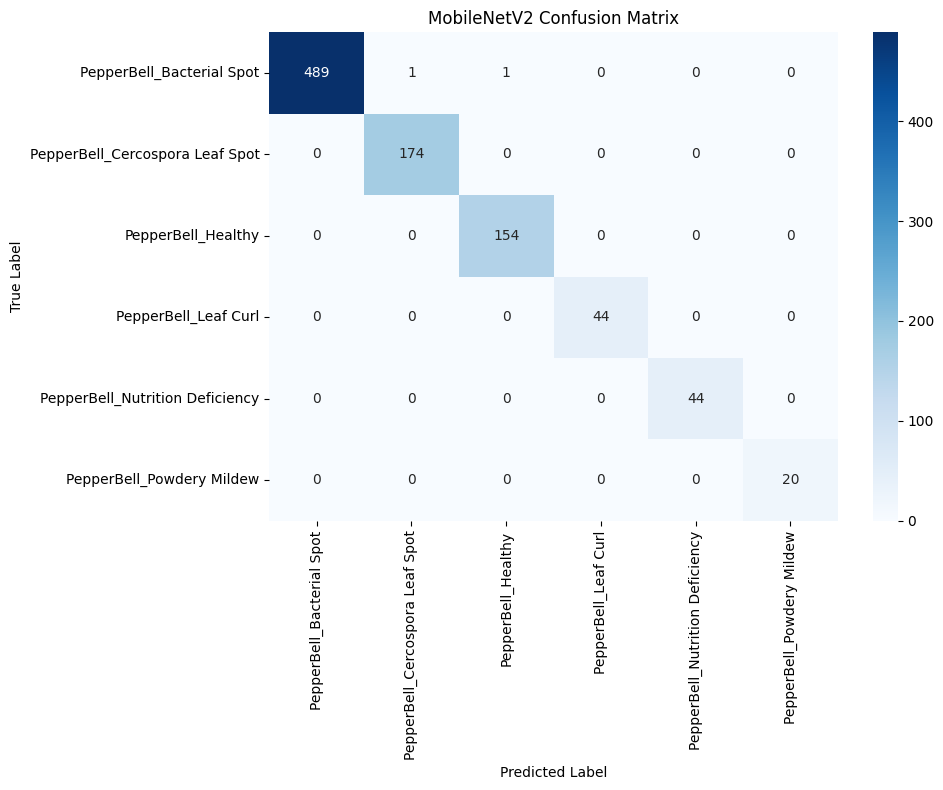

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MobileNetV2 Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

image_path = "/content/test8.jpeg"

img = load_img(
    image_path,
    target_size=(224, 224)
)

img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

predicted_class = np.argmax(prediction[0])
confidence = prediction[0][predicted_class]

print("Predicted Disease:", class_names[predicted_class])
print("Confidence:", f"{confidence * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
Predicted Disease: PepperBell_Bacterial Spot
Confidence: 88.60%


In [ ]:
for i, class_name in enumerate(class_names):
    print(
        f"{class_name}: "
        f"{prediction[0][i] * 100:.2f}%"
    )

PepperBell_Bacterial Spot: 88.60%
PepperBell_Cercospora Leaf Spot: 2.18%
PepperBell_Healthy: 0.05%
PepperBell_Leaf Curl: 3.69%
PepperBell_Nutrition Deficiency: 4.78%
PepperBell_Powdery Mildew: 0.70%


Model loaded successfully!
Image loaded successfully!


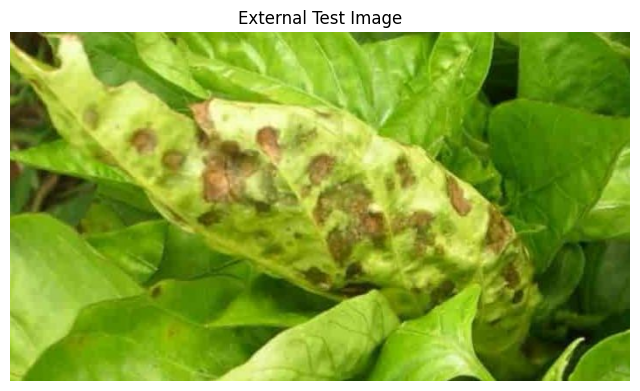



             EXTERNAL IMAGE TEST

TOP 1 PREDICTION
----------------------------
Class      : PepperBell_Bacterial Spot
Confidence : 94.94%

TOP 2 PREDICTION
----------------------------
Class      : PepperBell_Leaf Curl
Confidence : 2.40%

CONFIDENCE ANALYSIS
----------------------------
Difference between Top 1 and Top 2: 92.54%
Status: HIGH CONFIDENCE
Top 1 prediction is clearly ahead of Top 2.


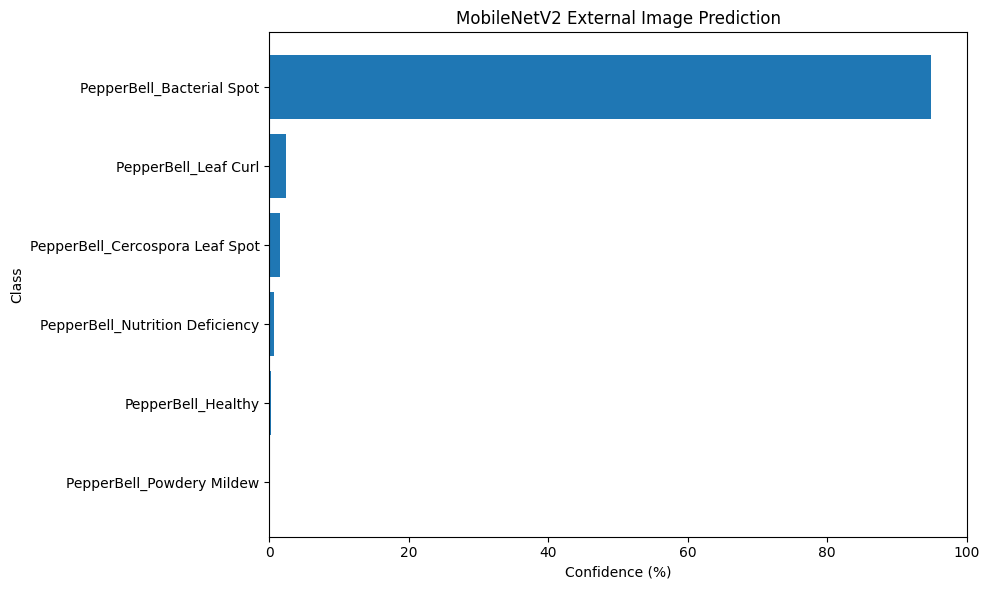

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ============================================================
# 1. PATHS
# ============================================================

MODEL_PATH = "/content/drive/MyDrive/capsicum detection /best_mobilenetv2_finetuned.keras"

IMAGE_PATH = "/content/test8.jpeg"


# ============================================================
# 2. CLASS NAMES
# ============================================================

CLASS_NAMES = [
    "PepperBell_Bacterial Spot",
    "PepperBell_Cercospora Leaf Spot",
    "PepperBell_Healthy",
    "PepperBell_Leaf Curl",
    "PepperBell_Nutrition Deficiency",
    "PepperBell_Powdery Mildew"
]


# ============================================================
# 3. IMAGE SIZE
# ============================================================

IMG_SIZE = (224, 224)


# ============================================================
# 4. LOAD MODEL
# ============================================================

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")


# ============================================================
# 5. LOAD EXTERNAL IMAGE
# ============================================================

image = Image.open(IMAGE_PATH).convert("RGB")

print("Image loaded successfully!")


# ============================================================
# 6. DISPLAY ORIGINAL IMAGE
# ============================================================

plt.figure(figsize=(8, 6))

plt.imshow(image)

plt.title("External Test Image")

plt.axis("off")

plt.show()


# ============================================================
# 7. PREPROCESS IMAGE
# ============================================================

resized_image = image.resize(IMG_SIZE)

img_array = np.array(resized_image)

img_array = np.expand_dims(img_array, axis=0)


# IMPORTANT:
# Your model already contains:
#
# layers.Rescaling(1./127.5, offset=-1)
#
# Therefore DO NOT use:
#
# tf.keras.applications.mobilenet_v2.preprocess_input()
#
# here.


# ============================================================
# 8. MAKE PREDICTION
# ============================================================

predictions = model.predict(
    img_array,
    verbose=0
)[0]


# ============================================================
# 9. SORT PREDICTIONS
# ============================================================

sorted_indices = np.argsort(predictions)[::-1]


# ============================================================
# 10. TOP 1
# ============================================================

top1_index = sorted_indices[0]

top1_class = CLASS_NAMES[top1_index]

top1_confidence = predictions[top1_index] * 100


# ============================================================
# 11. TOP 2
# ============================================================

top2_index = sorted_indices[1]

top2_class = CLASS_NAMES[top2_index]

top2_confidence = predictions[top2_index] * 100


# ============================================================
# 12. PRINT RESULTS
# ============================================================

print("\n")
print("=" * 60)
print("             EXTERNAL IMAGE TEST")
print("=" * 60)

print("\nTOP 1 PREDICTION")
print("----------------------------")

print(f"Class      : {top1_class}")
print(f"Confidence : {top1_confidence:.2f}%")


print("\nTOP 2 PREDICTION")
print("----------------------------")

print(f"Class      : {top2_class}")
print(f"Confidence : {top2_confidence:.2f}%")


# ============================================================
# 13. CONFIDENCE ANALYSIS
# ============================================================

difference = top1_confidence - top2_confidence

print("\nCONFIDENCE ANALYSIS")
print("----------------------------")

print(f"Difference between Top 1 and Top 2: {difference:.2f}%")

if top1_confidence >= 80:

    print("Status: HIGH CONFIDENCE")

elif top1_confidence >= 50:

    print("Status: MODERATE CONFIDENCE")

else:

    print("Status: LOW CONFIDENCE")


# Check whether the two predictions are close

if difference < 10:

    print("Warning: Top 1 and Top 2 predictions are very close.")

elif difference < 20:

    print("Notice: Top 1 and Top 2 predictions have moderate separation.")

else:

    print("Top 1 prediction is clearly ahead of Top 2.")



# ============================================================
# 15. BAR CHART
# ============================================================

sorted_classes = [
    CLASS_NAMES[i]
    for i in sorted_indices
]

sorted_probabilities = [
    predictions[i] * 100
    for i in sorted_indices
]


plt.figure(figsize=(10, 6))

plt.barh(
    sorted_classes[::-1],
    sorted_probabilities[::-1]
)

plt.xlabel("Confidence (%)")

plt.ylabel("Class")

plt.title("MobileNetV2 External Image Prediction")

plt.xlim(0, 100)

plt.tight_layout()

plt.show()